In [1]:
# from pathlib import Path

# PROJECT_DIR = Path("football_adda")

# directories = [
#     "assets/characters/rahim",
#     "assets/characters/karim",
#     "assets/characters/jamal",
#     "assets/backgrounds",
#     "audio",
#     "animation",
#     "output"
# ]

# for directory in directories:
#     (PROJECT_DIR / directory).mkdir(parents=True, exist_ok=True)

# print("Project structure created!")

Project structure created!


In [2]:
# %pip install pillow numpy opencv-python matplotlib

In [3]:
from pathlib import Path

PROJECT_DIR = Path("football_adda")

CHARACTER_DIR = PROJECT_DIR / "assets" / "characters"
BACKGROUND_DIR = PROJECT_DIR / "assets" / "backgrounds"
ANIMATION_DIR = PROJECT_DIR / "animation"
OUTPUT_DIR = PROJECT_DIR / "output"

for folder in [CHARACTER_DIR, BACKGROUND_DIR, ANIMATION_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PRESENTERS = {
    "Rahim": {
        "folder": "rahim",
        "shirt": (35, 91, 155),
        "hair": (35, 29, 27),
        "skin": (218, 166, 125),
        "role": "HOST"
    },
    "Karim": {
        "folder": "karim",
        "shirt": (25, 133, 91),
        "hair": (45, 31, 24),
        "skin": (190, 133, 96),
        "role": "MESSI FAN"
    },
    "Jamal": {
        "folder": "jamal",
        "shirt": (157, 52, 55),
        "hair": (32, 28, 25),
        "skin": (207, 151, 111),
        "role": "RONALDO FAN"
    }
}

for person in PRESENTERS.values():
    (CHARACTER_DIR / person["folder"]).mkdir(exist_ok=True)

print("Character folders are ready.")

Character folders are ready.


In [4]:
from PIL import Image, ImageDraw

CHAR_WIDTH = 420
CHAR_HEIGHT = 500

def draw_character(name, mouth_open=False):

    config = PRESENTERS[name]

    img = Image.new(
        "RGBA",
        (CHAR_WIDTH, CHAR_HEIGHT),
        (0, 0, 0, 0)
    )

    draw = ImageDraw.Draw(img)

    skin = config["skin"]
    hair = config["hair"]
    shirt = config["shirt"]

    # Body / shoulders
    draw.rounded_rectangle(
        (35, 325, 385, 550),
        radius=100,
        fill=shirt
    )

    # Shirt collar
    draw.polygon(
        [(160, 330), (210, 390), (260, 330)],
        fill=(245, 245, 245)
    )

    # Neck
    draw.rounded_rectangle(
        (165, 285, 255, 385),
        radius=25,
        fill=skin
    )

    # Ears
    draw.ellipse((75, 155, 135, 240), fill=skin)
    draw.ellipse((285, 155, 345, 240), fill=skin)

    # Face
    draw.ellipse(
        (95, 65, 325, 345),
        fill=skin,
        outline=(75, 50, 40),
        width=4
    )

    # Hair
    draw.pieslice(
        (90, 35, 330, 220),
        start=180,
        end=360,
        fill=hair
    )

    draw.rounded_rectangle(
        (95, 115, 130, 190),
        radius=15,
        fill=hair
    )

    # Eyebrows
    draw.line((145, 175, 190, 168), fill=hair, width=9)
    draw.line((230, 168, 275, 175), fill=hair, width=9)

    # Eyes
    draw.ellipse((145, 185, 190, 225), fill="white")
    draw.ellipse((230, 185, 275, 225), fill="white")

    draw.ellipse((161, 195, 180, 220), fill=(35, 35, 35))
    draw.ellipse((246, 195, 265, 220), fill=(35, 35, 35))

    # Nose
    draw.line(
        (210, 210, 198, 255, 222, 255),
        fill=(145, 95, 70),
        width=5
    )

    # Mouth
    if mouth_open:
        draw.ellipse(
            (178, 275, 242, 320),
            fill=(80, 20, 30),
            outline=(70, 30, 30),
            width=3
        )
        draw.arc(
            (183, 275, 237, 310),
            start=180,
            end=360,
            fill=(255, 255, 255),
            width=5
        )
    else:
        draw.arc(
            (175, 270, 245, 315),
            start=10,
            end=170,
            fill=(90, 35, 35),
            width=5
        )

    return img


# Generate all six character states
for name, config in PRESENTERS.items():

    folder = CHARACTER_DIR / config["folder"]

    closed = draw_character(name, mouth_open=False)
    opened = draw_character(name, mouth_open=True)

    closed.save(folder / "closed.png")
    opened.save(folder / "open.png")

    print(f"{name}: character images created")

Rahim: character images created
Karim: character images created
Jamal: character images created


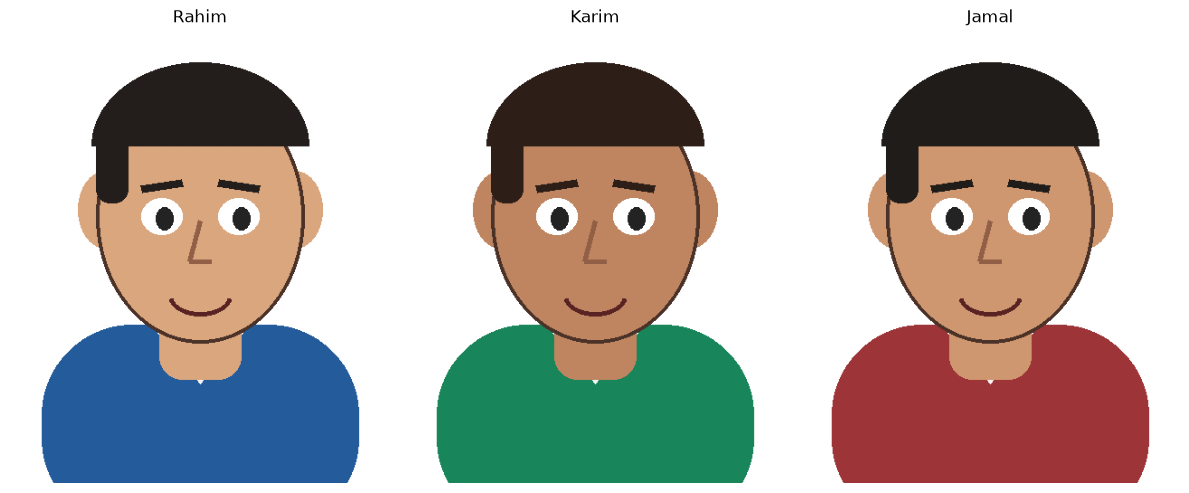

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, name in zip(axes, PRESENTERS.keys()):

    config = PRESENTERS[name]

    character = Image.open(
        CHARACTER_DIR / config["folder"] / "closed.png"
    )

    ax.imshow(character)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

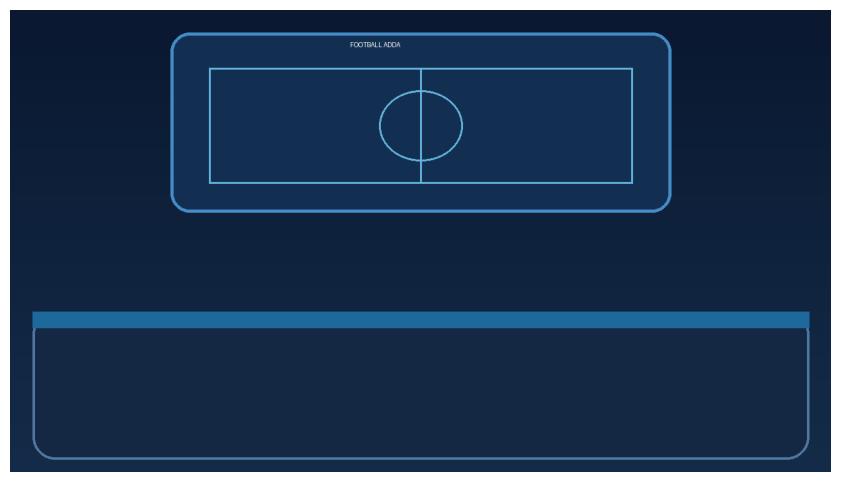

In [6]:
from PIL import Image, ImageDraw

W, H = 1280, 720

studio = Image.new("RGB", (W, H), (12, 25, 49))
draw = ImageDraw.Draw(studio)

# Background gradient
for y in range(H):
    ratio = y / H

    color = (
        int(10 + 10 * ratio),
        int(24 + 20 * ratio),
        int(48 + 25 * ratio)
    )

    draw.line((0, y, W, y), fill=color)

# Studio screen
draw.rounded_rectangle(
    (250, 35, 1030, 315),
    radius=30,
    fill=(18, 47, 82),
    outline=(70, 140, 200),
    width=5
)

# Football pitch graphic
draw.rectangle(
    (310, 90, 970, 270),
    outline=(100, 180, 220),
    width=3
)

draw.line(
    (640, 90, 640, 270),
    fill=(100, 180, 220),
    width=3
)

draw.ellipse(
    (575, 125, 705, 235),
    outline=(100, 180, 220),
    width=3
)

draw.text(
    (530, 48),
    "FOOTBALL ADDA",
    fill=(255, 255, 255)
)

# Desk
draw.rounded_rectangle(
    (35, 470, 1245, 700),
    radius=35,
    fill=(20, 40, 68),
    outline=(80, 120, 160),
    width=4
)

draw.rectangle(
    (35, 470, 1245, 495),
    fill=(30, 105, 155)
)

studio.save(BACKGROUND_DIR / "studio.png")

plt.figure(figsize=(12, 6))
plt.imshow(studio)
plt.axis("off")
plt.show()

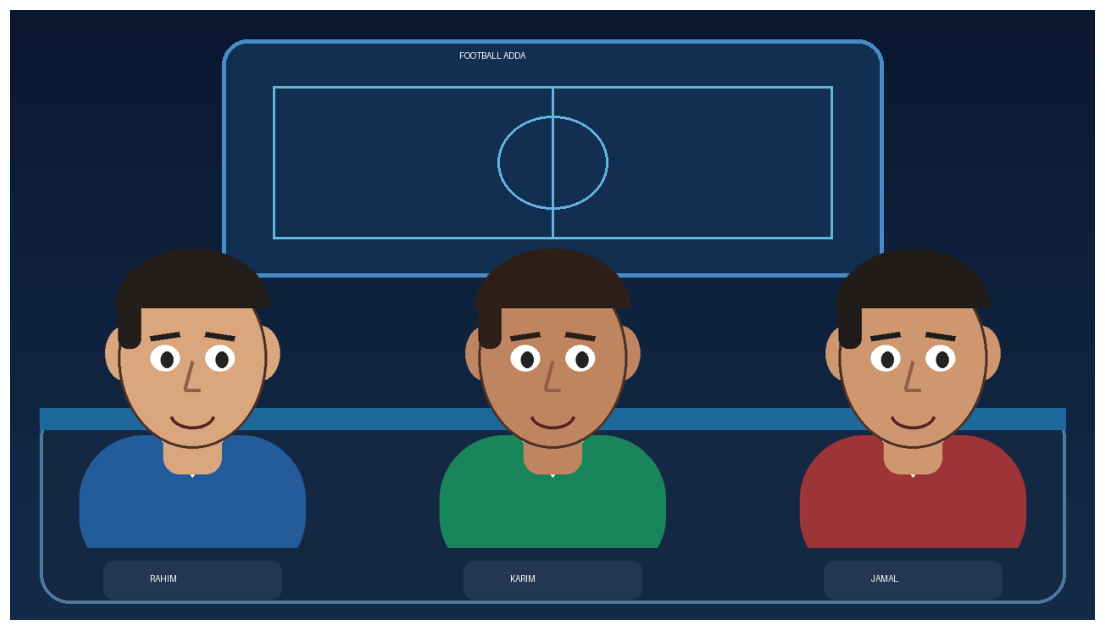

In [7]:
from PIL import Image, ImageDraw

def render_panel(active_speaker=None, mouth_open=False):

    scene = Image.open(
        BACKGROUND_DIR / "studio.png"
    ).convert("RGBA")

    positions = {
        "Rahim": (55, 255),
        "Karim": (480, 255),
        "Jamal": (905, 255)
    }

    for name, position in positions.items():

        config = PRESENTERS[name]

        state = "open" if (
            name == active_speaker and mouth_open
        ) else "closed"

        character_path = (
            CHARACTER_DIR /
            config["folder"] /
            f"{state}.png"
        )

        character = Image.open(character_path).convert("RGBA")

        character = character.resize((320, 380))

        scene.alpha_composite(character, position)

    draw = ImageDraw.Draw(scene)

    # Presenter nameplates
    for name, position in positions.items():

        x, y = position

        is_active = name == active_speaker

        color = (25, 145, 210) if is_active else (35, 55, 80)

        draw.rounded_rectangle(
            (x + 55, 650, x + 265, 695),
            radius=12,
            fill=color
        )

        draw.text(
            (x + 110, 665),
            name.upper(),
            fill=(255, 255, 255)
        )

    return scene.convert("RGB")


# Render the full panel
panel = render_panel()

panel.save(OUTPUT_DIR / "football_adda_panel.png")

plt.figure(figsize=(14, 8))
plt.imshow(panel)
plt.axis("off")
plt.show()

In [8]:
import time

frames = []

speaker_sequence = [
    "Rahim",
    "Karim",
    "Jamal",
    "Rahim",
    "Karim",
    "Jamal"
]

for speaker in speaker_sequence:

    # Mouth closed
    frames.append(
        render_panel(
            active_speaker=speaker,
            mouth_open=False
        )
    )

    # Mouth open
    frames.append(
        render_panel(
            active_speaker=speaker,
            mouth_open=True
        )
    )

gif_path = ANIMATION_DIR / "football_adda_panel_demo.gif"

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=250,
    loop=0
)

print("Panel animation created:", gif_path)

Panel animation created: football_adda/animation/football_adda_panel_demo.gif


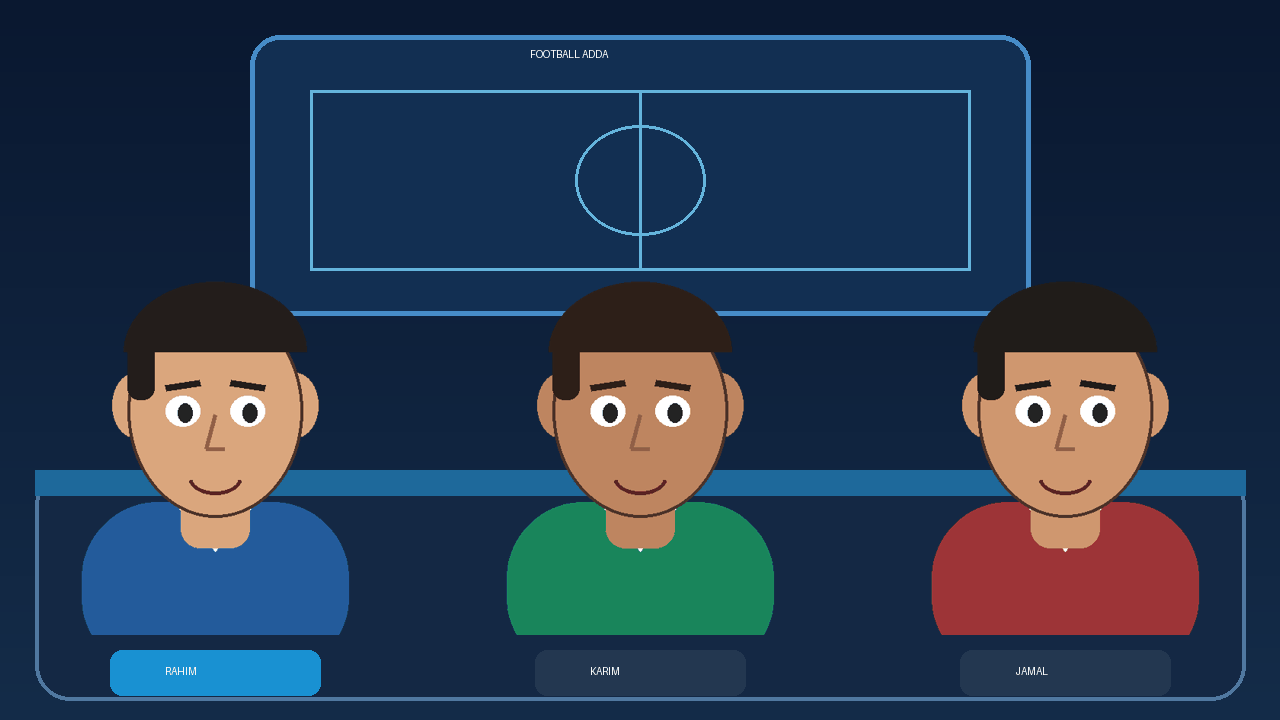

In [9]:
from IPython.display import display, Image as IPyImage

display(IPyImage(filename=str(gif_path)))
